# Adaboost / Regressor

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `cardekho.csv`.  
**Methods referenced:** `DecisionTreeRegressor`, `AdaBoostRegressor`, `ColumnTransformer`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


> **Evaluation correction:** Some evaluation calls originally passed predictions before the ground-truth labels. These calls now use `metric(y_test, y_pred)`. The saved outputs of corrected cells were cleared; rerun the notebook in order to regenerate them. Other historical outputs have not been recomputed.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV

In [2]:
df = pd.read_csv("cardekho.csv")

In [3]:
df.head(10)

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000
5,5,Maruti Wagon R,Maruti,Wagon R,8,35000,Individual,Petrol,Manual,18.90,998,67.10,5,350000
6,6,Hyundai i10,Hyundai,i10,8,40000,Dealer,Petrol,Manual,20.36,1197,78.90,5,315000
7,7,Maruti Wagon R,Maruti,Wagon R,3,17512,Dealer,Petrol,Manual,20.51,998,67.04,5,410000
8,8,Hyundai Venue,Hyundai,Venue,2,20000,Individual,Petrol,Automatic,18.15,998,118.35,5,1050000
9,12,Maruti Swift,Maruti,Swift,4,28321,Dealer,Petrol,Manual,16.60,1197,85.00,5,511000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


In [5]:
df.drop("Unnamed: 0", axis = 1, inplace = True)

In [6]:
df.describe()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


In [7]:
df["seats"].value_counts()

seats
5    12910
7     1922
8      311
6      127
4       77
9       55
2        7
0        2
Name: count, dtype: int64

In [8]:
df[df["seats"] == 0]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
3217,Honda City,Honda,City,18,40000,Individual,Petrol,Manual,13.00,1493,100.00,0,115000
12619,Nissan Kicks,Nissan,Kicks,2,10000,Individual,Diesel,Manual,19.39,1461,108.49,0,1154000


In [9]:
df[df["car_name"] == "Honda City"]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
23,Honda City,Honda,City,6,50000,Individual,Petrol,Manual,17.4,1497,117.3,5,750000
27,Honda City,Honda,City,14,77253,Dealer,Petrol,Manual,17.7,1497,78.0,5,145000
37,Honda City,Honda,City,6,31180,Dealer,Petrol,Automatic,18.0,1497,117.3,5,700000
67,Honda City,Honda,City,8,70000,Individual,Petrol,Manual,16.8,1497,116.3,5,545000
79,Honda City,Honda,City,7,69000,Dealer,Diesel,Manual,25.1,1498,98.6,5,550000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15325,Honda City,Honda,City,7,220000,Dealer,Diesel,Manual,26.0,1498,98.6,5,550000
15330,Honda City,Honda,City,7,110000,Individual,Diesel,Manual,26.0,1498,98.6,5,490000
15369,Honda City,Honda,City,9,54311,Dealer,Petrol,Manual,16.8,1497,116.3,5,465000
15385,Honda City,Honda,City,10,28147,Dealer,Petrol,Manual,17.0,1497,118.0,5,500000


In [10]:
df[df["car_name"] == "Nissan Kicks"]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
1259,Nissan Kicks,Nissan,Kicks,1,15000,Individual,Petrol,Manual,14.23,1330,153.87,5,1000000
2485,Nissan Kicks,Nissan,Kicks,1,7500,Individual,Diesel,Manual,20.45,1461,108.50,5,850000
3111,Nissan Kicks,Nissan,Kicks,2,4000,Dealer,Petrol,Manual,14.23,1498,104.55,5,890000
4937,Nissan Kicks,Nissan,Kicks,2,40000,Individual,Diesel,Manual,19.39,1461,108.00,5,1200000
9645,Nissan Kicks,Nissan,Kicks,2,11687,Trustmark Dealer,Petrol,Manual,14.23,1498,104.55,5,880000
12619,Nissan Kicks,Nissan,Kicks,2,10000,Individual,Diesel,Manual,19.39,1461,108.49,0,1154000
13160,Nissan Kicks,Nissan,Kicks,2,10000,Individual,Petrol,Manual,14.23,1498,104.55,5,950000
14275,Nissan Kicks,Nissan,Kicks,2,6200,Individual,Diesel,Manual,19.39,1461,108.00,5,1450000


In [11]:
df.loc[df["seats"] == 0, "seats"] = 5

In [12]:
df.loc[df.duplicated()]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
197,Honda City,Honda,City,8,70000,Individual,Petrol,Manual,16.80,1497,116.30,5,545000
360,Maruti Baleno,Maruti,Baleno,2,5000,Individual,Petrol,Automatic,21.40,1197,83.10,5,686000
1353,Maruti Swift Dzire,Maruti,Swift Dzire,4,50000,Individual,Diesel,Manual,28.40,1248,74.02,5,680000
1429,Maruti Wagon R,Maruti,Wagon R,13,100000,Individual,Petrol,Manual,18.90,1061,67.00,5,150000
1485,Hyundai i20,Hyundai,i20,3,50000,Individual,Petrol,Manual,18.60,1197,81.83,5,625000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15229,Maruti Swift,Maruti,Swift,8,80000,Individual,Diesel,Manual,22.90,1248,74.00,5,350000
15324,Maruti Wagon R,Maruti,Wagon R,6,50000,Individual,CNG,Manual,26.60,998,58.16,5,450000
15367,Tata Tiago,Tata,Tiago,4,30000,Individual,Petrol,Manual,23.84,1199,84.00,5,350000
15378,Hyundai Grand,Hyundai,Grand,6,30000,Individual,Petrol,Manual,18.90,1197,82.00,5,450000


In [13]:
df = df.drop_duplicates(keep = "first", ignore_index = True)

In [14]:
pd.set_option('display.float_format', '{:.2f}'.format)

In [15]:
df.describe()

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15244.00,15244.00,15244.00,15244.00,15244.00,15244.00,15244.00
mean,6.04,55639.58,19.70,1486.17,100.61,5.33,774701.45
std,3.02,51766.30,4.17,520.42,42.92,0.81,894676.08
min,0.00,100.00,4.00,793.00,38.40,2.00,40000.00
25%,4.00,30000.00,17.00,1197.00,74.00,5.00,385000.00
50%,6.00,50000.00,19.67,1248.00,88.50,5.00,559000.00
75%,8.00,70000.00,22.70,1582.00,117.30,5.00,825000.00
max,29.00,3800000.00,33.54,6592.00,626.00,9.00,39500000.00


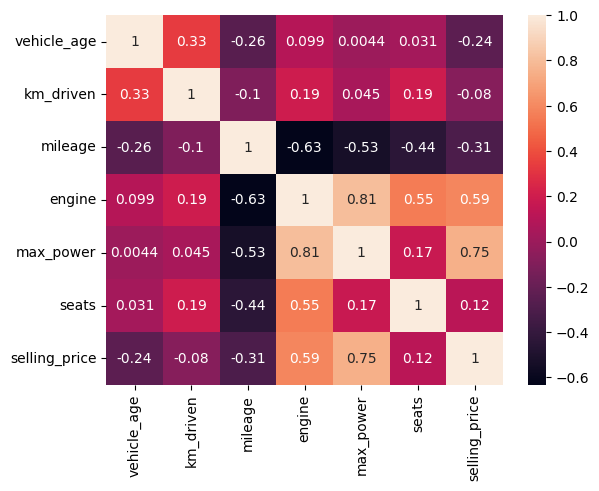

In [16]:
sns.heatmap(data = df.corr(numeric_only = True), annot = True)
plt.show()

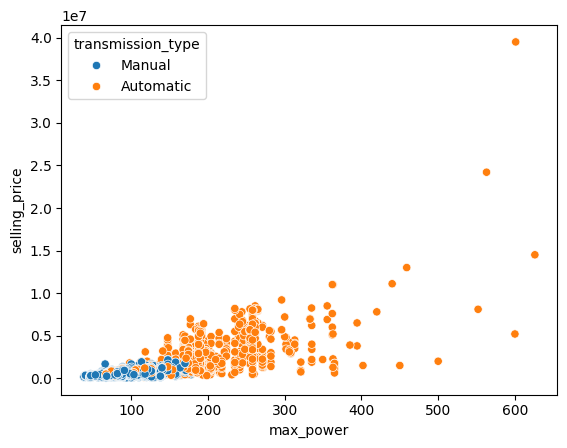

In [17]:
sns.scatterplot(data = df, x = "max_power", y = "selling_price", hue = "transmission_type")
plt.show()

In [18]:
df.loc[df["max_power"] > 450]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
1170,Bentley Continental,Bentley,Continental,9,9000,Dealer,Petrol,Automatic,9.50,5998,626.00,4,14500000
3785,Ferrari GTC4Lusso,Ferrari,GTC4Lusso,2,3800,Dealer,Petrol,Automatic,4.00,3855,601.00,4,39500000
9109,Porsche Cayenne,Porsche,Cayenne,12,126000,Individual,Petrol,Automatic,8.50,4806,500.00,5,2000000
9637,Mercedes-Benz S-Class,Mercedes-Benz,S-Class,3,4000,Dealer,Petrol,Automatic,7.81,4663,459.00,4,13000000
9954,Bentley Continental,Bentley,Continental,9,37500,Dealer,Petrol,Automatic,6.00,5998,600.00,5,5200000
10870,Rolls-Royce Ghost,Rolls-Royce,Ghost,4,5000,Individual,Petrol,Automatic,10.20,6592,563.00,4,24200000
12875,Bentley Continental,Bentley,Continental,10,30000,Dealer,Petrol,Automatic,8.60,5998,552.00,4,8100000


In [19]:
df.drop(index = [1170, 3785, 9109, 9637, 9954, 10870, 12875], inplace = True)

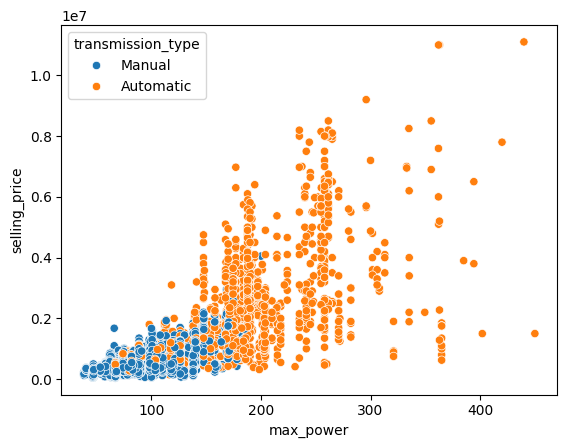

In [20]:
sns.scatterplot(data = df, x = "max_power", y = "selling_price", hue = "transmission_type")
plt.show()

In [21]:
df.loc[df["selling_price"] > 1500000]

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
12,Mini Cooper,Mini,Cooper,4,6000,Dealer,Petrol,Automatic,14.41,1998,189.08,5,3250000
58,Mahindra XUV500,Mahindra,XUV500,3,21500,Individual,Diesel,Automatic,15.10,2179,152.87,7,1650000
111,BMW 5,BMW,5,5,63000,Dealer,Diesel,Automatic,18.59,2993,261.49,5,2600000
129,Ford Endeavour,Ford,Endeavour,3,11387,Individual,Diesel,Automatic,10.91,3198,197.00,7,2900000
139,BMW 3,BMW,3,5,68000,Dealer,Diesel,Automatic,22.69,1995,190.00,5,2090000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15177,Toyota Innova,Toyota,Innova,5,70000,Dealer,Diesel,Manual,13.68,2393,147.80,8,1640000
15196,Jeep Compass,Jeep,Compass,3,70000,Individual,Diesel,Manual,16.30,1956,170.00,5,1750000
15198,BMW 5,BMW,5,4,30000,Dealer,Diesel,Automatic,22.48,1995,187.74,5,3975000
15218,Mercedes-Benz E-Class,Mercedes-Benz,E-Class,3,25000,Dealer,Diesel,Automatic,10.00,2148,170.00,5,4450000


In [22]:
df = df.loc[df["selling_price"] < 1500000]

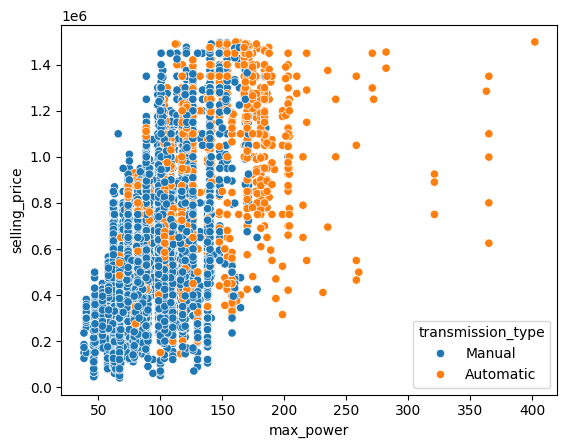

In [23]:
sns.scatterplot(data = df, x = "max_power", y = "selling_price", hue = "transmission_type")
plt.show()

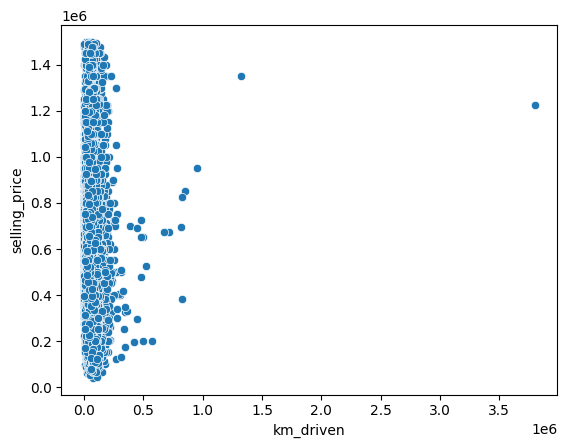

In [24]:
sns.scatterplot(data = df, x = "km_driven", y = "selling_price")
plt.show()

In [25]:
df = df[df["km_driven"] < 1000000]

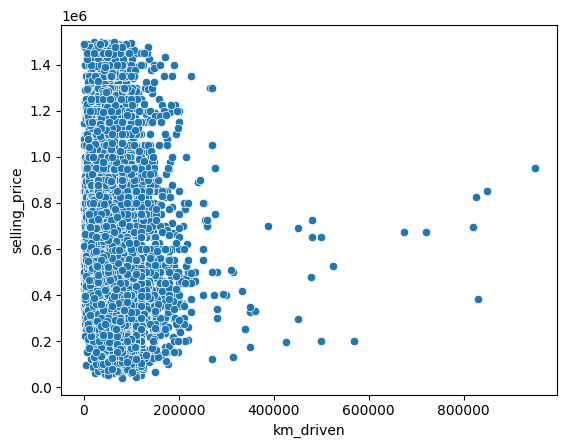

In [26]:
sns.scatterplot(data = df, x = "km_driven", y = "selling_price")
plt.show()

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13890 entries, 0 to 15243
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   car_name           13890 non-null  object 
 1   brand              13890 non-null  object 
 2   model              13890 non-null  object 
 3   vehicle_age        13890 non-null  int64  
 4   km_driven          13890 non-null  int64  
 5   seller_type        13890 non-null  object 
 6   fuel_type          13890 non-null  object 
 7   transmission_type  13890 non-null  object 
 8   mileage            13890 non-null  float64
 9   engine             13890 non-null  int64  
 10  max_power          13890 non-null  float64
 11  seats              13890 non-null  int64  
 12  selling_price      13890 non-null  int64  
dtypes: float64(2), int64(5), object(6)
memory usage: 1.5+ MB


In [29]:
categorical_cols = df.select_dtypes("object").columns.to_list()

In [30]:
df[categorical_cols].columns

Index(['car_name', 'brand', 'model', 'seller_type', 'fuel_type',
       'transmission_type'],
      dtype='object')

In [31]:
df[categorical_cols].nunique()

car_name             93
brand                24
model                93
seller_type           3
fuel_type             4
transmission_type     2
dtype: int64

In [33]:
unique_values = df[categorical_cols].nunique()

In [34]:
onehot_cols = ['seller_type', 'fuel_type', 'transmission_type']
freq_cols = ['car_name', 'brand', 'model']

In [35]:
X = df.drop("selling_price", axis = 1)
y = df["selling_price"]

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

In [37]:
for col in freq_cols:
    freq = X_train[col].value_counts() / len(X_train)

    X_train[col + "_freq"] = X_train[col].map(freq)
    X_test[col + "_freq"] = X_test[col].map(freq)

    mean_freq = freq.mean()
    X_test[col + "_freq"] = X_test[col].map(freq).fillna(mean_freq)


In [38]:
X_train.head(10)

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,car_name_freq,brand_freq,model_freq
11018,Honda Amaze,Honda,Amaze,6,68000,Dealer,Diesel,Manual,25.80,1498,98.60,5,0.03,0.10,0.03
6762,Maruti Swift Dzire,Maruti,Swift Dzire,3,140000,Individual,Diesel,Manual,28.40,1248,74.02,5,0.06,0.36,0.06
958,Maruti Wagon R,Maruti,Wagon R,6,18650,Dealer,Petrol,Manual,21.50,1197,81.80,5,0.05,0.36,0.05
6625,Datsun RediGO,Datsun,RediGO,2,4646,Dealer,Petrol,Manual,22.70,799,53.64,5,0.01,0.01,0.01
15195,Hyundai i10,Hyundai,i10,12,8500,Dealer,Petrol,Automatic,19.20,1197,80.00,5,0.03,0.21,0.03
13469,Maruti Alto,Maruti,Alto,9,52865,Dealer,Petrol,Manual,23.95,998,67.05,5,0.06,0.36,0.06
13532,Datsun RediGO,Datsun,RediGO,3,15000,Individual,Petrol,Manual,22.50,999,68.00,5,0.01,0.01,0.01
12217,Maruti Swift Dzire,Maruti,Swift Dzire,10,89000,Dealer,Diesel,Manual,19.30,1248,73.90,5,0.06,0.36,0.06
4400,Hyundai Creta,Hyundai,Creta,4,53000,Individual,Diesel,Manual,21.38,1396,88.70,5,0.02,0.21,0.02
11158,Maruti Wagon R,Maruti,Wagon R,10,60000,Individual,Petrol,Manual,18.90,998,67.10,5,0.05,0.36,0.05


In [39]:
X_test.head(10)

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,car_name_freq,brand_freq,model_freq
5088,Honda City,Honda,City,5,66000,Dealer,Diesel,Manual,26.00,1498,98.60,5,0.05,0.10,0.05
3393,Mahindra XUV500,Mahindra,XUV500,9,90000,Individual,Diesel,Manual,15.10,2179,140.00,7,0.02,0.07,0.02
10004,Hyundai Venue,Hyundai,Venue,2,27000,Dealer,Petrol,Manual,18.27,998,118.35,5,0.00,0.21,0.00
13665,Honda City,Honda,City,13,122671,Individual,Petrol,Manual,17.70,1497,78.00,5,0.05,0.10,0.05
4375,Honda City,Honda,City,13,78000,Individual,Petrol,Manual,17.00,1497,118.00,5,0.05,0.10,0.05
4982,Mahindra Bolero,Mahindra,Bolero,10,95000,Individual,Diesel,Manual,13.60,2523,63.00,7,0.02,0.07,0.02
12012,Maruti Baleno,Maruti,Baleno,5,42700,Dealer,Petrol,Manual,21.40,1197,83.10,5,0.03,0.36,0.03
7634,Maruti Wagon R,Maruti,Wagon R,12,45641,Dealer,Petrol,Manual,18.90,998,67.10,5,0.05,0.36,0.05
2773,Hyundai i20,Hyundai,i20,8,70000,Individual,Diesel,Manual,21.90,1396,88.76,5,0.06,0.21,0.06
9318,Hyundai i20,Hyundai,i20,5,55000,Dealer,Petrol,Manual,18.60,1197,81.83,5,0.06,0.21,0.06


In [40]:
X_train

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,car_name_freq,brand_freq,model_freq
11018,Honda Amaze,Honda,Amaze,6,68000,Dealer,Diesel,Manual,25.80,1498,98.60,5,0.03,0.10,0.03
6762,Maruti Swift Dzire,Maruti,Swift Dzire,3,140000,Individual,Diesel,Manual,28.40,1248,74.02,5,0.06,0.36,0.06
958,Maruti Wagon R,Maruti,Wagon R,6,18650,Dealer,Petrol,Manual,21.50,1197,81.80,5,0.05,0.36,0.05
6625,Datsun RediGO,Datsun,RediGO,2,4646,Dealer,Petrol,Manual,22.70,799,53.64,5,0.01,0.01,0.01
15195,Hyundai i10,Hyundai,i10,12,8500,Dealer,Petrol,Automatic,19.20,1197,80.00,5,0.03,0.21,0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999,Ford Figo,Ford,Figo,9,80000,Individual,Diesel,Manual,20.00,1399,68.00,5,0.02,0.05,0.02
10273,Maruti Wagon R,Maruti,Wagon R,4,75000,Dealer,CNG,Manual,33.54,998,67.04,5,0.05,0.36,0.05
8794,Honda City,Honda,City,14,75075,Dealer,Petrol,Manual,17.70,1497,78.00,5,0.05,0.10,0.05
13883,Maruti Celerio,Maruti,Celerio,2,7000,Individual,Petrol,Manual,23.10,998,67.04,5,0.02,0.36,0.02


In [41]:
X_train = X_train.drop(freq_cols, axis = 1)
X_test = X_test.drop(freq_cols, axis = 1)

In [42]:
transformer = ColumnTransformer(
    transformers = [("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"),onehot_cols)],
    remainder = "passthrough"
)

In [43]:
X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)

In [44]:
model = AdaBoostRegressor()

In [45]:
model.fit(X_train, y_train)

,estimator,None
,n_estimators,50
,learning_rate,1.0
,loss,'linear'
,random_state,None


In [46]:
y_pred = model.predict(X_test)

In [47]:
print("r2 score: ", r2_score(y_pred, y_test))
print("mean squared error: ", mean_squared_error(y_test, y_pred))
print("mean absolute error: ", mean_absolute_error(y_test, y_pred))

r2 score:  0.4272195590129064
mean squared error:  22580448365.808437
mean absolute error:  122627.9065611452


In [48]:
params = {
    "n_estimators" : [50, 80, 100, 120],
    "learning_rate" : [0.001, 0.01, 0.1, 1.0, 2.0],
    "loss" : ["linear", "square", "exponential"]
}

In [49]:
rcv = RandomizedSearchCV(estimator=AdaBoostRegressor(), param_distributions=params, scoring='r2', cv=5)
rcv.fit(X_train, y_train)

,estimator,AdaBoostRegressor()
,param_distributions,"{'learning_rate': [0.001, 0.01, ...], 'loss': ['linear', 'square', ...], 'n_estimators': [50, 80, ...]}"
,n_iter,10
,scoring,'r2'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [50]:
print(rcv.best_params_)
y_pred = rcv.predict(X_test)
print("r2 score: ", r2_score(y_pred, y_test))
print("mean squared error: ", mean_squared_error(y_test, y_pred))
print("mean absolute error: ", mean_absolute_error(y_test, y_pred))

{'n_estimators': 120, 'loss': 'linear', 'learning_rate': 0.1}
r2 score:  0.601191333282729
mean squared error:  18620069601.22386
mean absolute error:  104592.884146598
